# Welcome

你好，我是Siying。欢迎👏阅读本篇内容。


首先，我想让大家仔细想想下面这些题，一些的咨询专家认为如下战略理念都很重要。你怎么看待这些说法呢? 

::: {.callout-tip } 

| 营销理念 | 你认为对？还是错？ |
| --- | --- |
| A. 客户忠诚度体现了品牌实力，而非品牌体量 |  |
| B. 维护老客，比拉新更重要 |  |
| C. 品牌不应泛化竞争，要选择那些与自己定位一致的对手 |  |
| D. 顾客的购买，必有特定理由 |  |
| E. 顾客可以被细分、区隔 |  |
| F. 80% 营收由 20% 的重度客户贡献 |  |


:::

如果你认为以上都是对的，那么你很有可能正被错误的假设蒙蔽。（您看，就算是营销公司的行业专家，也会犯上面这些错



本项目将向您展示：

通过数据，一个顾客一辈子大概会花多少钱是可预测的，并且这离不开这个三个概念：

1. **负二项分布**

    “80% 营收来自 20% 的重度客户“ 这一现象，它其实是负二项分布定律。
    

2. **用户分层**

    用户从进入到流失，期间一直在不同层级流动。用户分层其实只是购买节律和金额的单一写照。
    

3. **客户终生价值**

    客户会在你这里花多少钱。
   


<hr>
<br>
🚶

老板今天来上班了，可以观察他平时喝几杯咖啡or可乐：🥤

有的老板是“牛饮型”，一天3杯；🥤🥤🥤

有的老板是“品鉴型”，一天就抿上几口。🥤

而且老板今天喝几杯，也许纯粹看心情，甚至有些老板戒咖啡...

——而这就是泊松分布（随机事件）

> 将所有人喝咖啡or可乐的统计下来，有的人偶尔买一次，有的人买很多次，这种波动很大、极度不平衡的分布就是——负二项分布（NBD）💡

以及依据老板过去喝咖啡的历史情况，我们就可以推测 TA 今天是否会喝咖啡的概率 = PAlive

> **PAlive** 原本用于于药物试验场景中，它表示患者存活的概率。（很多统计相关的方法论都来自医学领域，因为关联到患者生命，需要考虑得格外严谨与慎重）这种叫法后来迁移到各种领域，这里表示顾客流失与否的概率

<br>

所有消费市场都是满足**NBD分布**。💡

接下来我们结合数据集，对零售交易数据进行建模，来预测用户是否购买和PAlive；

在**RFM 分析**中，我要分析数据整体是如何分布的，并将其整理为分类；

在RFM之后，则是对数据进行建模，并最后估计出**客户终生价值（CLV）**；

以及结合RFM分析与聚类的分层方法，可以将顾客细分为可进行差异化策略运营的群体。


# 数据预处理




> 本项目对零售数据建模，以预测客户流失，预测客户终生价值作为目标。项目数据来自公开数据[uk礼品店在线零售商ii](https://archive.ics.uci.edu/dataset/502/online+retail+ii)。


欧，（你不用安装任何东西——

code 即代码块的下方已显示运行结果

你只需要一直往下滑就可以

...

## import

In [2]:
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager
from scipy.stats import nbinom, poisson

import seaborn as sns
from lifetimes.utils import summary_data_from_transaction_data
# from lifetimes import BetaGeoFitter
# from lifetimes import GammaGammaFitter
# from lifetimes.plotting import plot_period_transactions
# from lifetimes.utils import *

from pymc_marketing.clv import rfm_train_test_split, rfm_summary,plotting
from pymc_marketing.clv import BetaGeoModel,GammaGammaModel
import arviz as az
import arviz_plots as azp
from arviz_base.labels import MapLabeller

import xarray as xr

for f in ["/System/Library/Fonts/STHeiti Medium.ttc", "/System/Library/Fonts/STHeiti Light.ttc","/System/Library/Fonts/NotoSerifCJK-Regular.ttc"]:
    try:
        font_manager.fontManager.addfont(f)
    except Exception:
        pass
plt.rcParams.update({"font.family": ["STHeiti", "Arial Unicode MS", "DejaVu Sans"],
                     "axes.unicode_minus": False, "figure.facecolor": "white",
                     "axes.facecolor": "white", "axes.grid": False})
my_font = font_manager.FontProperties(fname="/System/Library/Fonts/STHeiti Medium.ttc")
font_path = "/System/Library/Fonts/STHeiti Medium.ttc"


SRC = "./online_retail_II.xlsx"
OUT = "./cleaned_online_retail_II.csv"

In [3]:
xl = pd.ExcelFile(SRC)
print("SHEETS:", xl.sheet_names)
frames = {}
for sheet in xl.sheet_names:
    df = pd.read_excel(SRC, sheet_name=sheet)
    print(f"\n=== Sheet: {sheet} ===")
    print("shape:", df.shape)
    print("columns:", list(df.columns))
    print(df.head(3).to_string())
    print("\ndtypes:\n", df.dtypes)
    print("\nmissing:\n", df.isna().sum())
    print("\ndescribe:\n", df.describe(include="all").to_string())
    frames[sheet] = df


full = pd.concat(frames.values(), ignore_index=True)
print("\n=== Combined ===")
print("shape:", full.shape)
full["InvoiceDate"] = pd.to_datetime(full["InvoiceDate"], errors="coerce")
print("date range:", full["InvoiceDate"].min(), "->", full["InvoiceDate"].max())
print("n customers (non-null Customer ID):", full["Customer ID"].nunique())
print("n invoices:", full["Invoice"].nunique())
print("negative Quantity rows:", (full["Quantity"] <= 0).sum())
print("nonpositive Price rows:", (full["Price"] <= 0).sum())
print("null Customer ID rows:", full["Customer ID"].isna().sum())
print("null Description rows:", full["Description"].isna().sum())
print("\nduplicated rows (full):", full.duplicated().sum())
print("countries:", full["Country"].value_counts().head(10).to_dict())

SHEETS: ['Year 2009-2010', 'Year 2010-2011']

=== Sheet: Year 2009-2010 ===
shape: (525461, 8)
columns: ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']
  Invoice StockCode                          Description  Quantity         InvoiceDate  Price  Customer ID         Country
0  489434     85048  15CM CHRISTMAS GLASS BALL 20 LIGHTS        12 2009-12-01 07:45:00   6.95      13085.0  United Kingdom
1  489434    79323P                   PINK CHERRY LIGHTS        12 2009-12-01 07:45:00   6.75      13085.0  United Kingdom
2  489434    79323W                  WHITE CHERRY LIGHTS        12 2009-12-01 07:45:00   6.75      13085.0  United Kingdom

dtypes:
 Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
Price                 float64
Customer ID           float64
Country                object
dtype: object

missing:
 Invoice             0
Stock

columns: ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']

上面是数据集的“体检报告”：

你需要知道它有这些维度：发票号、商品编码、商品描述、数量、发票日期、单价、客户ID、国家

其中 发票号 、发票日期、数量 、单价、客户ID 是本次重要的分析维度

我们需要从中计算得到 **购买频率、购买时间、购买次数、购买金额**等信息

（数据清洗过程这里就简单带过了）



数据处理步骤分为 ：import, clean, view  

你也可以直接跳到view的部分，进入分析阶段

...




## clean 

In [4]:
full.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [5]:
df = full.copy()
# print("raw rows:", len(df))


数据整体比较干净，为了便于分析，对数据集做以下处理。

1. 剔除 Customer ID 、缺失行
2. 仅保留 Quantity > 0 且 Price > 0 的正常交易（退货/坏账剔除）
3. 删除完全重复行
4. InvoiceDate 更正为pandas适用的时间格式  -> datetime
5. 用金额和单价计算字段-总价 TotalPrice = Quantity * Price

In [6]:
df = df.dropna(subset=["Customer ID"]).copy()
print("after drop null Customer ID:", len(df))

# 2. keep normal transactions only
df = df[(df["Quantity"] > 0) & (df["Price"] > 0)]
print("after Quantity>0 & Price>0:", len(df))

# 3. drop full duplicates
df = df.drop_duplicates()
print("after drop duplicates:", len(df))


after drop null Customer ID: 824364
after Quantity>0 & Price>0: 805549
after drop duplicates: 779425


In [7]:
# 3.1 剔除非商品代码（）
NON_GOODS_CODES = ["POST", "DOT", "C2", "M", "BANK CHARGES"]  # 非商品代码（ 手动检查发现这些数据可能不是'真商品',比如邮费之类的) 
mask = df["StockCode"].isin(NON_GOODS_CODES)
print(f"non-goods rows dropped: {mask.sum()}  ({(df.loc[mask, 'Quantity']*df.loc[mask, 'Price']).sum():.0f})")
df = df[~mask]
print("after drop non-goods:", len(df))

non-goods rows dropped: 2779  (301328)
after drop non-goods: 776646


In [8]:
# 4. datetime
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
df = df.dropna(subset=["InvoiceDate"])
df["Customer ID"] = df["Customer ID"].astype(int)
print("after datetime conversion:", len(df))

# 5. feature
df["TotalPrice"] = df["Quantity"] * df["Price"]

# sanity
print("\ndate range:", df["InvoiceDate"].min(), "->", df["InvoiceDate"].max())
print("customers:", df["Customer ID"].nunique())
print("invoices:", df["Invoice"].nunique())
print("min/max TotalPrice:", round(df["TotalPrice"].min(), 2), "~", round(df["TotalPrice"].max(), 2))


after datetime conversion: 776646

date range: 2009-12-01 07:45:00 -> 2011-12-09 12:50:00
customers: 5861
invoices: 36644
min/max TotalPrice: 0.0 ~ 168469.6


## view data

审查数据基础情况：

In [9]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,TotalPrice
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,30.0


从 Quantity x Price 计算得到总价`TotalPrice`

In [11]:
df["TotalPrice"] = df["Quantity"] * df["Price"] # 这个也存到csv中

In [12]:
df.to_csv(OUT, index=False)
print("\nsaved ->", OUT, "rows:", len(df))


saved -> ./cleaned_online_retail_II.csv rows: 776646


In [13]:
print(f"行数: {len(df):,} | 订单: {df['Invoice'].nunique():,}")


行数: 776,646 | 订单: 36,644


# 单变量分析

接下来，对一些重要的变量(购买频次、购买间隔，近期购买时间等变)进行可视化和简单分析

如果你想看用户分层的部分，也可以直接跳到 RFM分析 的章节


## 购买时间分析

In [10]:
df = pd.read_csv(OUT,
                 parse_dates=["InvoiceDate"])


In [11]:

# 按订单去重
ord = df.drop_duplicates("Invoice").copy()
ord["hour"] = ord["InvoiceDate"].dt.hour
ord["dow"] = ord["InvoiceDate"].dt.dayofweek          # 0=周一 ... 6=周日
ord["month"] = ord["InvoiceDate"].dt.month
ord["ym"] = ord["InvoiceDate"].dt.to_period("M")

MON = ["1月", "2月", "3月", "4月", "5月", "6月", "7月", "8月", "9月", "10月", "11月", "12月"]
DOW = ["周一", "周二", "周三", "周四", "周五", "周六", "周日"]

hour_cnt = ord["hour"].value_counts().sort_index()
dow_cnt = ord["dow"].value_counts().sort_index()
monthly = ord.groupby("ym").agg(orders=("Invoice","count"), sales=("TotalPrice","sum"))
ym_df = monthly.reset_index()
ym_df["year"] = ym_df["ym"].dt.year
ym_df["mon"] = ym_df["ym"].dt.month


pivot = ord.pivot_table(index="dow", columns="hour", values="Invoice", aggfunc="count",
                        fill_value=0).reindex(index=range(7), columns=range(24)).fillna(0)

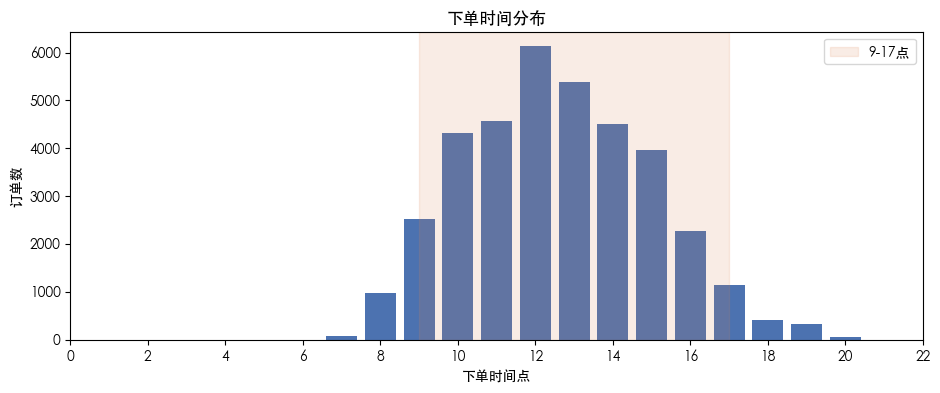

In [12]:
fig, ax = plt.subplots(figsize=(11,4))
ax.bar(hour_cnt.index, hour_cnt.values, color="#4C72B0")
ax.grid(False) 
ax.set_title("下单时间分布")
ax.axvspan(9,17, color="#DD8452", alpha=0.15, label="9-17点")
ax.set_xticks(range(0,24,2)); ax.set_xlabel("下单时间点"); ax.set_ylabel("订单数")
ax.legend()

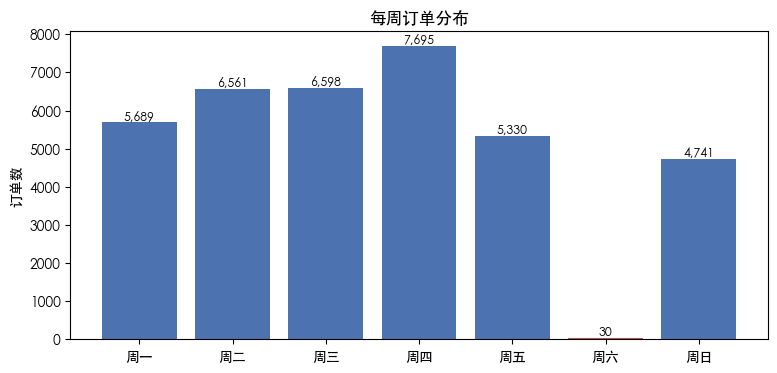

In [17]:
fig, ax = plt.subplots(figsize=(9,4))
colors = ["#C44E52" if d==5 else "#4C72B0" for d in range(7)]
bars = ax.bar(DOW, [dow_cnt.get(d,0) for d in range(7)], color=colors)
ax.set_ylabel("订单数")
ax.set_title("每周订单分布")
ax.grid(False) 
for i, d in enumerate(range(7)):
    ax.text(i, dow_cnt.get(d,0), f"{dow_cnt.get(d,0):,}", ha="center", va="bottom", fontsize=9)

(从数据中得到了额外的结果： **周六仅 30** 单 → 周六是停业的)


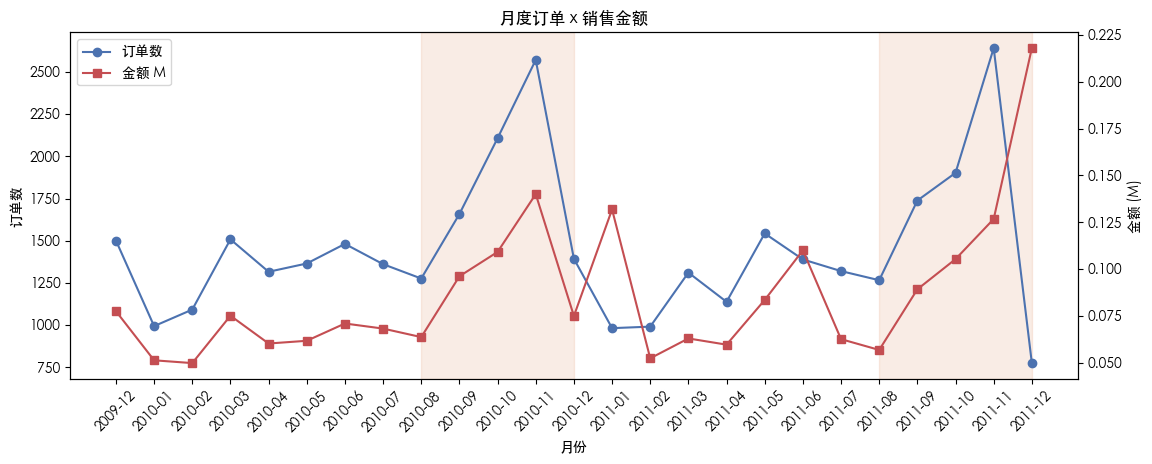

In [18]:
fig, ax = plt.subplots(figsize=(13,4.5))
ax.plot(monthly.index.astype(str), monthly["orders"], marker="o", color="#4C72B0", label="订单数")
ax.set_ylabel("订单数")
ax.set_xlabel("月份")

ax2 = ax.twinx()
ax2.plot(monthly.index.astype(str), monthly["sales"]/1e6, marker="s", color="#C44E52", label="金额 M")
ax2.set_ylabel("金额 (M)")
ax.grid(False) 
ax2.grid(False)
ax.set_title("月度订单 x 销售金额")
h1,l1 = ax.get_legend_handles_labels()
h2,l2 = ax2.get_legend_handles_labels()
ax.legend(h1+h2, l1+l2, loc="upper left")
# plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
ax.axvspan('2010-08', '2010-12', color="#DD8452", alpha=0.15, label="峰值窗口")
ax.axvspan('2011-08', '2011-12', color="#DD8452", alpha=0.15, label="峰值窗口")

ax.tick_params(axis='x', rotation=45)

至此，前两张图都符合常识。 而从这张时序图中，我们发现每年8月-12月出现明显的峰值。

这个峰值会影响我们后续的分析吗？嗯，这可能是一个潜在的因素，但是谁知道呢～

将每年的订单走势，重叠在一起，这种规律可以看得更清楚：

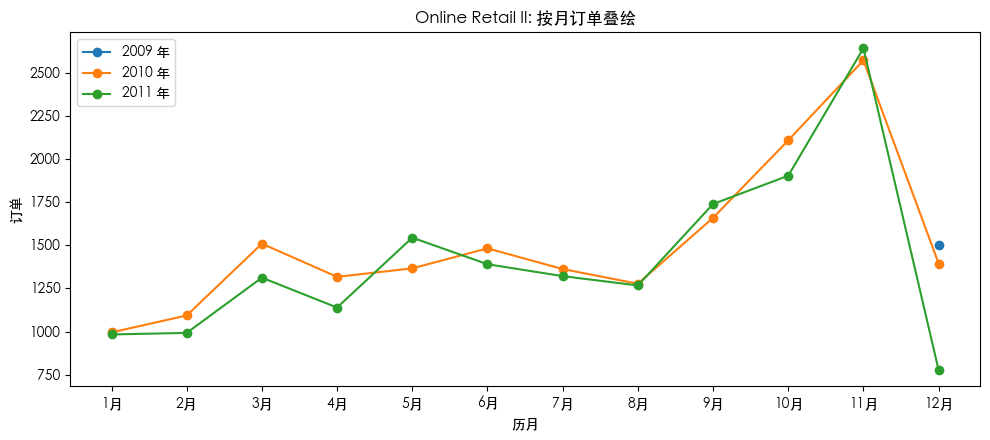

In [19]:
ym_df = monthly.reset_index()
ym_df["year"] = ym_df["ym"].dt.year
ym_df["mon"] = ym_df["ym"].dt.month
fig, ax = plt.subplots(figsize=(10, 4.5))
for y in sorted(ym_df["year"].unique()):
    sub = ym_df[ym_df["year"] == y]
    ax.plot(sub["mon"], sub["orders"], marker="o", label=f"{y} 年")
ax.set_xticks(range(1, 13)); ax.set_xticklabels([MON[m] for m in range(0, 12)])
ax.set_xlabel("历月")
ax.set_ylabel("订单")
ax.grid(False)
ax.legend()
ax.set_title("Online Retail II: 按月订单叠绘")
fig.tight_layout()


大部分的拐点和走势几乎重合。

峰值在圣诞节前的那一个月, 因为我们读取的是礼品店的零售数据，很符合实际场景。







> 关于 首次购买时间 
> 
> 数据从 2009-12 开始，而当月购买的 952 人 （占 16.2%）, 没有证据能够区分他们是新客还是老客，默认视为"新客"处理

## 购买间隔



CV=1.32
购买间隔(含同日多单): n=30,783 均值=51.6天 中位=25天
同日多单(0天)占比: 13.3% | 剔除0后: 均值=59.6天 中位=32天


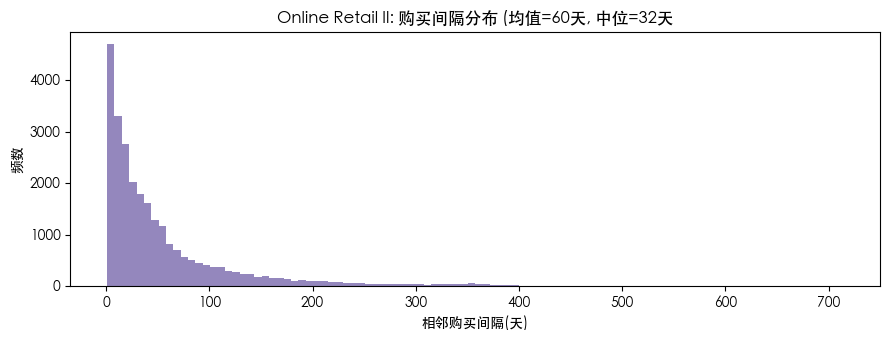

In [ ]:
# 每客户按时间排序，取相邻发票日期差（天）。同日多张发票 -> 0 天间隔
inv_dates = df.drop_duplicates("Invoice")[["Customer ID", "InvoiceDate"]].sort_values(
    ["Customer ID", "InvoiceDate"])
d = inv_dates.groupby("Customer ID")["InvoiceDate"].diff().dropna().dt.days
intervals = d.values.astype(float)
zero_share = (intervals == 0).mean()
intervals_pos = intervals[intervals > 0]
cv = intervals_pos.std() / intervals_pos.mean()
print(f"CV={cv:.2f}")
print(f"购买间隔(含同日多单): n={len(intervals):,} 均值={intervals.mean():.1f}天 中位={np.median(intervals):.0f}天")
print(f"同日多单(0天)占比: {zero_share:.1%} | 剔除0后: 均值={intervals_pos.mean():.1f}天 中位={np.median(intervals_pos):.0f}天")


fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(intervals_pos, bins=100, color="#8172B2", alpha=0.85)
ax.set_xlabel("相邻购买间隔(天)") 
ax.set_ylabel("频数")
ax.set_title(f"Online Retail II: 购买间隔分布 (均值={intervals_pos.mean():.0f}天, 中位={np.median(intervals_pos):.0f}天")
fig.tight_layout(); 

## 购买次数

我们可以同时计算这三个核心特征： `frequency`	`recency`	`T`

1.  frequency ：重复购买次数

2.  recency ： 距最近一次购买的时间

3.  T ： 首次购买到观察期的时间长度

In [21]:
summary_data = summary_data_from_transaction_data(
    df,
    customer_id_col='Customer ID',
    datetime_col='InvoiceDate',
    datetime_format="%Y-%m-%d %H:%M:%S",
    monetary_value_col="TotalPrice",
    observation_period_end=df['InvoiceDate'].max(),
    include_first_transaction=True

)


拿到 frequency 并统计复购客户占比：

未复购客户占比: 28.7% | 复购客户占比: 71.3%


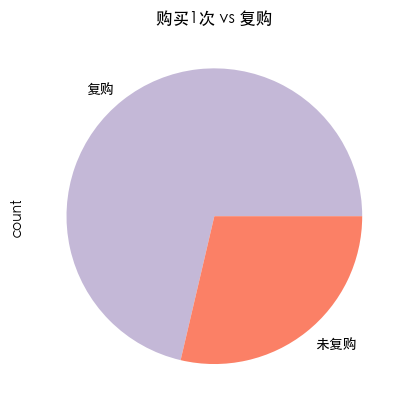

In [22]:
counts = (summary_data['frequency'] < 2).value_counts().rename(index={True:'未复购', False:'复购'})
counts.plot.pie(colors=["#c4b8d7","#FB8066"],startangle=0
                )    
plt.title('购买1次 vs 复购')
print(f"未复购客户占比: {(summary_data['frequency'] < 2).mean():.1%} | 复购客户占比: {(summary_data['frequency'] >= 2).mean():.1%}")

In [23]:
x = summary_data['frequency']
print(f"\n购买次数: 均值={x.mean():.2f} 中位={x.median():.0f} p90={x.quantile(.9):.0f} max={x.max()}")
print(f"只买一次占比: {(x==1).mean():.1%} | 买≥5次占比: {(x>=5).mean():.1%}")


购买次数: 均值=5.62 中位=3 p90=12 max=248.0
只买一次占比: 28.7% | 买≥5次占比: 34.9%


进一步查看不同复购频率的占比：

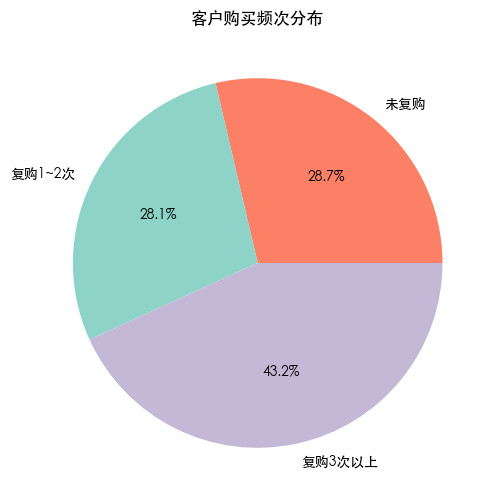

未复购客户占比: 28.7% (共 1680 人)
复购1~2次客户占比: 28.1% (共 1649 人)
复购3次以上客户占比: 43.2% (共 2532 人)


In [24]:

bins = [-float('inf'), 1, 3, float('inf')]
labels = ['未复购', '复购1~2次', '复购3次以上']


conditions = [
    summary_data['frequency'] == 1,
    (summary_data['frequency'] >= 2) & (summary_data['frequency'] <= 3),
    summary_data['frequency'] > 3
]
choices = ['未复购', '复购1~2次', '复购3次以上']

freq_group = np.select(conditions, choices, default='other')
counts = pd.Series(freq_group).value_counts().reindex(labels) # 保持固定顺序

plt.figure(figsize=(6, 6))
counts.plot.pie(
    autopct='%1.1f%%',              # 显示百分比
    startangle=0,                  # 起始角度
    colors=["#FB8066", "#8dd3c7", "#c4b8d7"
    ] # 自定义三种颜色
)
plt.title('客户购买频次分布')
plt.ylabel('') 
plt.show()

total_cust = len(summary_data)
for label in labels:
    cnt = (freq_group == label).sum()
    print(f"{label}客户占比: {cnt / total_cust:.1%} (共 {cnt} 人)")

## 购买金额

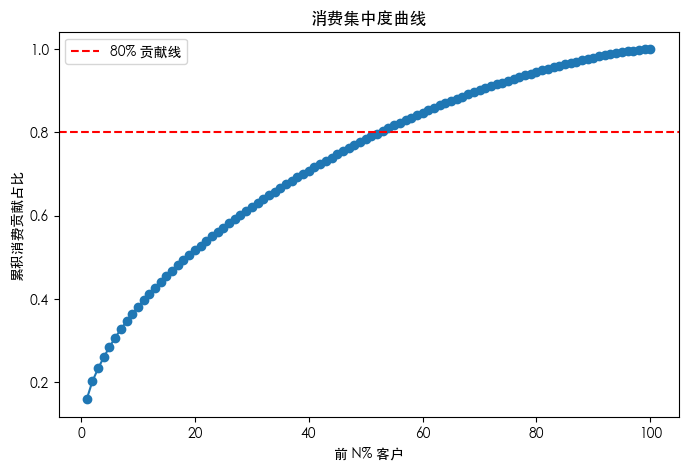

In [25]:
# 按消费降序
monetary_sorted = summary_data.sort_values("monetary_value", ascending=False)
total_spend = summary_data["monetary_value"].sum()

# 计算前 1%~50% 各百分位的累积贡献
percentiles = np.arange(1, 101)
cum_share = []
for p in percentiles:
    n = int(len(monetary_sorted) * p / 100)
    share = monetary_sorted.head(n)["monetary_value"].sum() / total_spend
    cum_share.append(share)

plt.figure(figsize=(8,5))
plt.plot(percentiles, cum_share, marker='o', linestyle='-')
plt.axhline(y=0.8, color='r', linestyle='--', label='80% 贡献线')
plt.xlabel("前 N% 客户")
plt.ylabel("累积消费贡献占比")
plt.title("消费集中度曲线")
plt.legend()
plt.show()

<u> 大约**50%的客户**贡献了80%的销售额</u>

::: {.callout-tip} 

帕累托法则（80/20法则）也许和你想的不同，“80%的销售来自20%的重度客户“，是对这一法则的误导

2/8这个比例很少出现, 且不会80/20这么极端

多数情况下，随着时间推移，这个80%的比率会来到50%

:::


>
> 很多人会有这么一个误区：
> 
> “我只要抓住前20%的客户，就等于抓住了80%的营收“
>
>要对这些头部用户做画像，定向投放
>
>
> 这种归因方式其实是错误的，只要客户之间有差异，头部就会存在，这是天然的分布结果**（Ehrenberg, A. S. C., Uncles, M. D., & Goodhardt, G. J. (2004).）**


# RFM 分析

##  客户分层

用户分层的方法：

一种做法是按R、F、M打分，每个维度分为3-5个等级，组合形成用户分层。

比如可以基于经验，建立规则，来分层：


| R | F | M | 分类 |
| ---- | ---- | ---- | ---- |
| 4 | 4 | 4 | Champions |
| 3 | 3 | 3 | Loyal |
| 4 | 2 | * | New |
| 2 | 4 | 4 | At Risk-High Value |
| 2 | 3 | * | Hibernating |
| 2 | 2 | 2 | Lost |
| 3 | 2 | 2 | Potential |
| * | * | * | Others |






将交易数据从3个维度进行排序+切分，若迁移到企业自己的场景
 
 除却这三个维度，肯定有更多维度值得挖掘，鼓励基于原有理论，创新建立自己的框架



在单变量分析中已经对这值的数量级有了大概的概念：

接下来的问题是如何结合这三个维度去给用户分类。


In [60]:
df = pd.read_csv(OUT,
                 parse_dates=["InvoiceDate"])


把客户均匀分成 5 组，为其分配权重，得到最终的打分

（这个切分仅展示处理流程，不参与落地，后面还会使用**聚类**来重新评估RFM的切分）

In [ ]:
end_date = df["InvoiceDate"].max() 
print("reference date:", end_date.date())
rfm = rfm_summary(
    df,
        customer_id_col='Customer ID',
        datetime_col='InvoiceDate',
        datetime_format="%Y-%m-%d %H:%M:%S",
        monetary_value_col='TotalPrice',
        observation_period_end=end_date,
        include_first_transaction=True
)

rfm = rfm.reset_index()

# 五分位打分（5=最好）。recency 越小越好 
def quartile_score(s, reverse=False):
    qs = pd.qcut(s.rank(method = "first"), 5, labels=[1, 2, 3, 4, 5], duplicates='drop')
    out = qs.astype(int)
    return 6 - out if reverse else out

rfm["R"] = quartile_score(rfm["recency"], reverse=True)
rfm["F"] = quartile_score(rfm["frequency"])
rfm["M"] = quartile_score(rfm["monetary_value"])

rfm["RFM_Score"] = rfm["R"].astype(int) * 100 + rfm["F"].astype(int) * 10 + rfm["M"].astype(int) # 代表r-f-m 三维分数,不是单纯的加权分数, 例如 R=5,F=5,M=1 的分数是 551, 而 R=1,F=5,M=5 的分数是 155, 这两个分数不能直接比较大小


reference date: 2011-12-09


## 客户消费分析

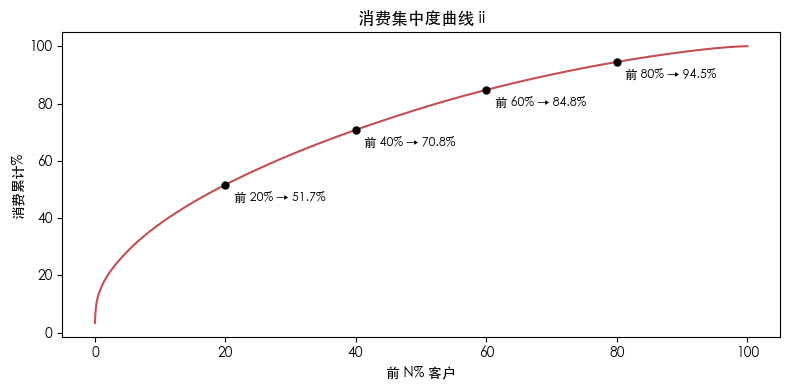

In [72]:

# 集中度曲线，前 x% 客户贡献了多少消费
srt = rfm.sort_values("monetary_value", ascending=False)["monetary_value"].values
cum = np.cumsum(srt) / srt.sum()
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(np.arange(1, len(cum) + 1) / len(cum) * 100, cum * 100, color="#C44E52")
for p in [20, 40, 60, 80]:
    k = int(round(len(cum) * p / 100))
    ax.scatter([p], [cum[k-1] * 100], color="black", zorder=5, s=25)
    ax.annotate(f"前 {p}% → {cum[k-1]*100:.1f}%", (p, cum[k-1] * 100),
                textcoords="offset points", xytext=(6, -12), fontsize=9)
plt.xlabel("前 N% 客户") 
ax.set_ylabel("消费累计%")
ax.set_title("消费集中度曲线 ii")
fig.tight_layout()
plt.show()

In [73]:
p20 = rfm["monetary_value"].quantile(0.2)
p40 = rfm["monetary_value"].quantile(0.4)
p60 = rfm["monetary_value"].quantile(0.6)
p80 = rfm["monetary_value"].quantile(0.8)
p90 = rfm["monetary_value"].quantile(0.9)
print(f"前 80% 客户贡献了 {p20:.2f} 的消费金额")
print(f"前 60% 客户贡献了 {p40:.2f} 的消费金额")
print(f"前 40% 客户贡献了 {p60:.2f} 的消费金额")
print(f"前 20% 客户贡献了 {p80:.2f} 的消费金额")
print(f"前 10% 客户贡献了 {p90:.2f} 的消费金额")

前 80% 客户贡献了 163.43 的消费金额
前 60% 客户贡献了 243.35 的消费金额
前 40% 客户贡献了 333.77 的消费金额
前 20% 客户贡献了 481.58 的消费金额
前 10% 客户贡献了 680.50 的消费金额


In [74]:
rfm

,index,customer_id,frequency,recency,monetary_value,R,F,M,RFM_Score
0,0,12346,8.0,325.0,9694.557500,2,4,5,245
1,1,12347,8.0,2.0,615.191250,5,5,5,555
2,2,12348,5.0,75.0,331.680000,3,4,3,343
3,3,12349,3.0,18.0,1226.230000,5,3,5,535
4,4,12350,1.0,310.0,294.400000,2,1,3,213
...,...,...,...,...,...,...,...,...,...
5856,5856,18283,19.0,3.0,139.944737,5,5,1,551
5857,5857,18284,1.0,431.0,411.680000,1,2,4,124
5858,5858,18285,1.0,660.0,377.000000,1,2,4,124
5859,5859,18286,2.0,476.0,623.215000,1,3,5,135


## RFM 分层

In [ ]:
seg_order = [
    "Champions 冠军",
    "Loyal 忠诚",
    "New 新客",
    "Promising 潜力",
    "NeedAttention 需关注",
    "AtRisk 预警",
    "CantLose 挽留",
    "Hibernating 沉睡",
    "Lost 流失"
]


# 先聚合，不急着 reindex
seg = rfm.groupby("Segment", dropna=False).agg(
    n=("customer_id", "size"),
    R=("recency", "mean"),
    F=("frequency", "mean"),
    M=("monetary_value", "mean"),
    total_monetary=("monetary_value", "sum"),
).round(2)

# 检查是否存在未定义的分层标签
unexpected = set(seg.index.dropna()) - set(seg_order)
print("未列入 seg_order 的标签:", unexpected)

# 再排序
seg = seg.reindex(seg_order)

# 先使用 rfm 总客户数作为分母
seg["pct_customers"] = (seg["n"] / rfm["customer_id"].nunique() * 100).round(1)

# 消费占比使用完整数据的消费总额作为分母
seg["pct_spend"] = (
    seg["total_monetary"] / rfm["monetary_value"].sum() * 100
).round(1)

print(seg.to_string())
print(f"RFM 客户数: {rfm['customer_id'].nunique():,} | 分层: {rfm['Segment'].nunique()} 类")

未列入 seg_order 的标签: set()
                      n       R      F       M  total_monetary  pct_customers  pct_spend
Segment                                                                                 
Champions 冠军        752   19.52  15.48  676.44       508682.75           12.8       20.9
Loyal 忠诚           1102   61.47   7.38  507.35       559097.90           18.8       22.9
New 新客              170   28.73   1.00  396.38        67384.34            2.9        2.8
Promising 潜力        173   36.58   1.69  429.82        74359.58            3.0        3.1
NeedAttention 需关注  1320   62.64   5.46  287.97       380121.58           22.5       15.6
AtRisk 预警           123  345.04   7.40  784.31        96470.63            2.1        4.0
CantLose 挽留         359  403.82   2.92  201.15        72213.84            6.1        3.0
Hibernating 沉睡     1063  422.83   2.02  543.03       577245.96           18.1       23.7
Lost 流失             799  452.79   1.71  127.10       101552.05           13.6        

                      n       R      F       M  total_monetary  pct_customers  pct_spend
Segment                                                                                 
Champions 冠军        752   19.52  15.48  676.44       508682.75           12.8       20.9
Loyal 忠诚           1102   61.47   7.38  507.35       559097.90           18.8       22.9
New 新客              170   28.73   1.00  396.38        67384.34            2.9        2.8
Promising 潜力        173   36.58   1.69  429.82        74359.58            3.0        3.1
NeedAttention 需关注  1320   62.64   5.46  287.97       380121.58           22.5       15.6
AtRisk 预警           123  345.04   7.40  784.31        96470.63            2.1        4.0
CantLose 挽留         359  403.82   2.92  201.15        72213.84            6.1        3.0
Hibernating 沉睡     1063  422.83   2.02  543.03       577245.96           18.1       23.7
Lost 流失             799  452.79   1.71  127.10       101552.05           13.6        4.2
RFM 客户数: 5,861 | 分层: 

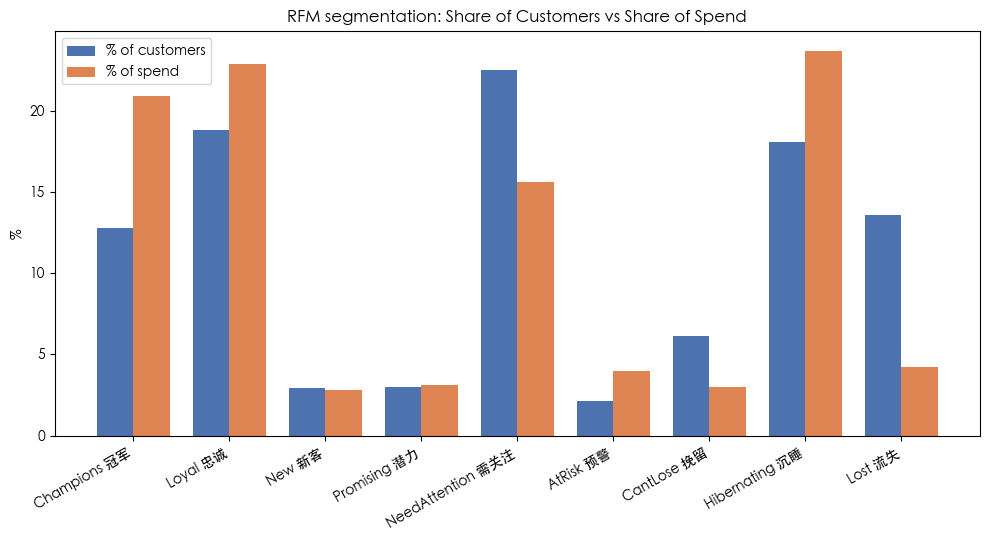

In [ ]:


# 分段规则优先级
def segment(row):
    r, f, m = row["R"], row["F"], row["M"]
    # 核心
    if r >= 4 and f >= 4 and m >= 4:
        return "Champions 冠军"
    if r >= 3 and f >= 3 and m >= 3:
        return "Loyal 忠诚"
    # 新客与潜力
    if r >= 4 and f <= 1 :
        return "New 新客"
    if r == 4 and f > 1 and f <= 2:
        return "Promising 潜力"
    # 风险与流失
    if r <= 3 and f >= 4 and m >= 4:
        return "AtRisk 预警"
    if r <= 2 and m >= 3:
        return "Hibernating 沉睡"
    if r <= 2 and f >= 2 and m >= 2:
        return "CantLose 挽留"
    # 需关注
    if r >= 3 and (f <= 2 or m <= 2):
        return "NeedAttention 需关注"
    return "Lost 流失"

rfm["Segment"] = rfm.apply(segment, axis=1)

seg_order = ["Champions 冠军", "Loyal 忠诚", "New 新客", "Promising 潜力",
             "NeedAttention 需关注", "AtRisk 预警", "CantLose 挽留", "Hibernating 沉睡", "Lost 流失"]

seg = rfm.groupby("Segment").agg(
    n=("customer_id", "size"),
    R=("recency", "mean"),
    F=("frequency", "mean"),
    M=("monetary_value", "mean"),
    total_monetary=("monetary_value", "sum"),
).round(2).reindex(seg_order)

seg["pct_customers"] = (seg["n"] / seg["n"].sum() * 100).round(1)
seg["pct_spend"] = (seg["total_monetary"] / seg["total_monetary"].sum() * 100).round(1)
print(seg.to_string())
print(f"RFM 客户数: {len(rfm):,} | 分层: {rfm['Segment'].nunique()} 类")

# 画像图：客户占比 vs 消费占比
fig, ax = plt.subplots(figsize=(10, 5.5))
x = np.arange(len(seg_order))
w = 0.38
ax.bar(x - w/2, seg["pct_customers"], w, label="% of customers", color="#4C72B0")
ax.bar(x + w/2, seg["pct_spend"], w, label="% of spend", color="#DD8452")
ax.set_xticks(x); ax.set_xticklabels(seg_order, rotation=30, ha="right")
ax.set_ylabel("%")
ax.set_title("RFM segmentation: Share of Customers vs Share of Spend")
ax.legend()
fig.tight_layout()

In [65]:
rfm.to_csv("./rfm.csv", index=False)


In [83]:
rfm.head()

,index,customer_id,frequency,recency,monetary_value,R,F,M,RFM_Score,Segment
0,0,12346,8.0,325.0,9694.55750,2,4,5,245,AtRisk 预警
1,1,12347,8.0,2.0,615.19125,5,5,5,555,Champions 冠军
2,2,12348,5.0,75.0,331.68000,3,4,3,343,Loyal 忠诚
3,3,12349,3.0,18.0,1226.23000,5,3,5,535,Loyal 忠诚
4,4,12350,1.0,310.0,294.40000,2,1,3,213,Hibernating 沉睡



数据说明：

对于用户`12346`，购买了8次（frequency），平均每次购买带来了9694.55的价值（monetary_value），距离上一次购物是400天前（recency）。

对于用户`12350`, 购买了1次，近期刚购买过，平均每次购买带来了294.4的价值。首次购买是310天之期。

## 分层可视化

In [194]:
print("--- Frequency 分位数 ---")
print(rfm["frequency"].quantile([0.1, 0.25, 0.5, 0.75, 0.9, 0.95]))

print("\n--- Monetary 分位数 ---")
print(rfm["monetary_value"].quantile([0.1, 0.25, 0.5, 0.75, 0.9, 0.95]))

print("\n--- Recency 分位数 ---")
print(rfm["recency"].quantile([0.1, 0.25, 0.5, 0.75, 0.9, 0.95]))

--- Frequency 分位数 ---
0.10     1.0
0.25     1.0
0.50     3.0
0.75     6.0
0.90    12.0
0.95    19.0
Name: frequency, dtype: float64

--- Monetary 分位数 ---
0.10    121.950000
0.25    182.761143
0.50    292.470000
0.75    432.886667
0.90    680.495000
0.95    961.596957
Name: monetary_value, dtype: float64

--- Recency 分位数 ---
0.10      8.0
0.25     25.0
0.50     95.0
0.75    379.0
0.90    534.0
0.95    625.0
Name: recency, dtype: float64


分位数不是必要，但是它可以帮你快速脑海中建立数据象限

In [192]:
for c in ["recency", "frequency", "monetary_value"]:
    s = rfm[c]
    sl = np.log1p(s)
    print(f"{c:<12} skew_orig={s.skew():>7.2f}  skew_log1p={sl.skew():>7.2f}")


recency      skew_orig=   0.89  skew_log1p=  -0.55
frequency    skew_orig=   9.84  skew_log1p=   0.97
monetary_value skew_orig=  45.74  skew_log1p=   0.14


In [ ]:
#| column: page  
import plotly.offline as pyo
pyo.init_notebook_mode(connected=True)

import plotly.express as px
import plotly.graph_objects as go

SEG_ORDER = ["Champions 冠军", "Loyal 忠诚", "New 新客", "Promising 潜力",
             "NeedAttention 需关注", "AtRisk 预警", "CantLose 挽留",
             "Hibernating 沉睡", "Lost 流失"]
PALETTE = ["#C0392B", "#E67E22", "#27AE60", "#5AC3AE", "#69A3C9",
           "#B56AD5", "#34495E", "#95A5A6", "#D5D8DC"]


color_map = dict(zip(SEG_ORDER, PALETTE))
present = [s for s in SEG_ORDER if s in set(rfm["Segment"])]

def ticks(vals, step_list):
    return [np.log1p(v) for v in step_list], [f"{v:,.0f}" for v in step_list]

F_TICKS = [0,10, 50, 100, 500, 1_000, 5_000, 10_000, 50_000, 500_000]
M_TICKS = [0,10, 50, 100,200,300, 400,500, 700,1000,1500, 2000, 5_000, 10_000,50_000, 100_000]
R_TICKS = [0, 1, 7, 30, 90, 180, 365, 740]

def axis_cfg(title, tickvals, ticktext, neg=False):
    tv = [-v for v in tickvals] if neg else tickvals
    return dict(title=title, tickvals=tv, ticktext=ticktext,
                gridcolor="#E5E7EB", showbackground=True,
                backgroundcolor="rgba(247,248,250,0.9)")

f_tv, f_tt = ticks(rfm["frequency"], F_TICKS)
m_tv, m_tt = ticks(rfm["monetary_value"], M_TICKS)
r_tv, r_tt = ticks(rfm["recency"], R_TICKS)

def hover(r):
    return (f"客户 {r['customer_id']}<br>"
            f"分层: {r['Segment']}<br>"
            f"Frequency: {r['frequency']:,.0f} 单<br>"
            f"Monetary: {r['monetary_value']:,.0f}<br>"
            f"Recency: {r['recency']:,.0f} 天<br>"
            f"RFM得分: {r['R']}{r['F']}{r['M']}")

# ---------------- log1p 3D 散点图 ----------------
fig_plotly = go.Figure()

for seg in present:
    g = rfm[rfm["Segment"] == seg]
    fig_plotly.add_trace(go.Scatter3d(
        x=np.log1p(g["frequency"]), 
        y=np.log1p(g["monetary_value"]), 
        z=-np.log1p(g["recency"]),
        mode="markers", 
        name=seg, 
        marker=dict(size=2.8, color=color_map.get(seg, "#BDC3C7"), opacity=0.65),
        text=g.apply(hover, axis=1), 
        hovertemplate="%{text}<extra></extra>",
        showlegend=True,
    ))

fig_plotly.update_layout(
    scene=dict(
        xaxis=axis_cfg("Frequence", f_tv, f_tt), 
        yaxis=axis_cfg("Monetary", m_tv, m_tt), 
        zaxis=axis_cfg("Recency", r_tv, r_tt, neg=True), 
        aspectmode="cube"
    ),
    title=dict(
        text="Online Retail II · RFM 分层", 
        x=0.5, font=dict(size=15)
    ),
    width=900, 
    height=650, 
    margin=dict(l=0, r=0, t=60, b=0),
    legend=dict(itemsizing="constant", font=dict(size=11)),
    paper_bgcolor="white",
)

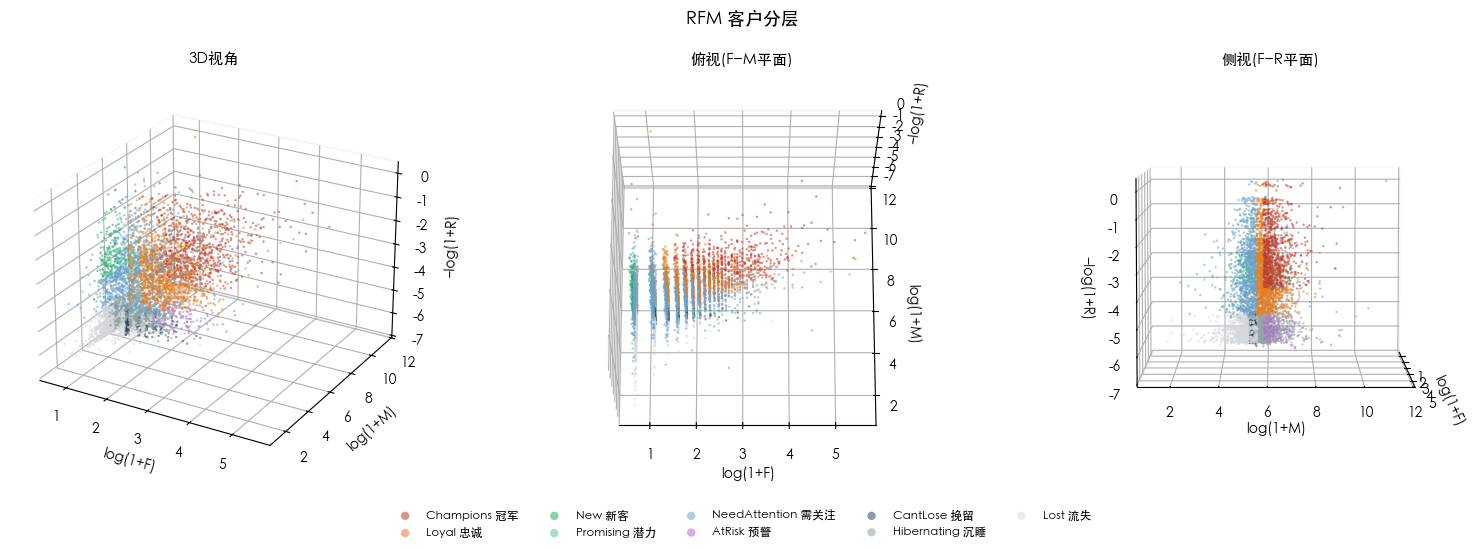

In [85]:
# from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

views = [(25, -60, "3D视角"), (70, -90, "俯视(F−M平面)"), (5, 0, "侧视(F−R平面)")]
fig = plt.figure(figsize=(16, 5.4))
for i, (elev, azim, name) in enumerate(views, start=1):
    ax = fig.add_subplot(1, 3, i, projection="3d")
    for seg in present:
        g = rfm[rfm["Segment"] == seg]
        ax.scatter(np.log1p(g["frequency"]), np.log1p(g["monetary_value"]), -np.log1p(g["recency"]),
                   s=3, c=color_map.get(seg, "#BDC3C7"), alpha=0.55,
                   label=seg, edgecolors="none")
    ax.set_xlabel("log(1+F)")
    ax.set_ylabel("log(1+M)")
    ax.set_zlabel("−log(1+R)")
    ax.view_init(elev=elev, azim=azim)
    ax.set_title(name, fontsize=11, fontweight="bold")
    ax.xaxis.pane.fill = False
    ax.yaxis.pane.fill = False
    ax.zaxis.pane.fill = False
handles, labels = fig.axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=5, frameon=False, fontsize=8.5,markerscale=3.5)
fig.suptitle("RFM 客户分层",
             fontsize=13, fontweight="bold", y=0.99)
fig.tight_layout(rect=[0, 0.09, 1, 0.96])

比起刚才那个表格，这个三维视图更加直观地表现出用户落在哪个分类里

这个就是用规则跑出来的用户群，虽然它不一定是最优的分层方法，但一定是最好理解的



用户分层就像化石中从中提取的一块切片，可以观察到客户的行为特征，帮助理解客户分布形状。

但是，这个视角就像给用户拍了一张“定格照片“，要用成长的眼光看待这些用户，就需要进一步的建模。


而对于**未来行为和价值的评估**，则基于**BG/NBD和Gamma-Gamma**的模型预测结果。





# Frequency X Recency 分析

## BG/NBD建模

接下来我们使用BG/NBD建模分析 Frequency/Recency

In [13]:
# train test split 
train_end_date = pd.Timestamp("2011-04-01")

bgm_data = rfm_train_test_split(
    df,
    customer_id_col='Customer ID',
    datetime_col='InvoiceDate',
    datetime_format="%Y-%m-%d %H:%M:%S",
    monetary_value_col='TotalPrice',
    time_unit = "D",
    train_period_end=train_end_date,
    test_period_end=df["InvoiceDate"].max(),
    include_first_transaction=False # 建模时仅考虑重复购买的情况，不考虑首次购买
)

bgm = BetaGeoModel(data=bgm_data)  
bgm.fit()  
bgm.fit_summary()  


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha, phi_dropout, kappa_dropout, r]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 15 seconds.


,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
alpha,61.621,2.099,57.592,65.368,0.049,0.035,1810.0,2034.0,1.0
phi_dropout,0.038,0.006,0.026,0.049,0.000,0.000,2151.0,2012.0,1.0
kappa_dropout,4.038,1.538,1.631,6.885,0.033,0.041,2160.0,2253.0,1.0
r,0.668,0.019,0.633,0.702,0.000,0.000,1851.0,1990.0,1.0
a,0.145,0.038,0.077,0.211,0.001,0.001,3093.0,3118.0,1.0
b,3.894,1.504,1.643,6.768,0.033,0.040,2146.0,2266.0,1.0


> 从上面的模拟后的参数结果，我们可以得到这样一些启发：
> 
>  r=0.66 < 1，差异显著，
> ==> 等价于客户的购买频率差异大（频繁购买和很少买的差异大）
>
>  alpha=61
> 
>  0.66/61 * 30 = 0.32 次/月
>  
>  ==> 等价于客户大概平均每 3个月回购一次东西 

## 实际数据 x 理论分布

在之前，已经分析了每列数据的基本情况。这次，让我们看看数据集 "顾客的购买"是否真的拟合‘NBD‘分布

Sampling: [recency_frequency]


Output()

<Axes: title={'center': 'Posterior Predictive Check for Customer Frequency'}, xlabel='Repeat Purchases', ylabel='% of Customer Population'>

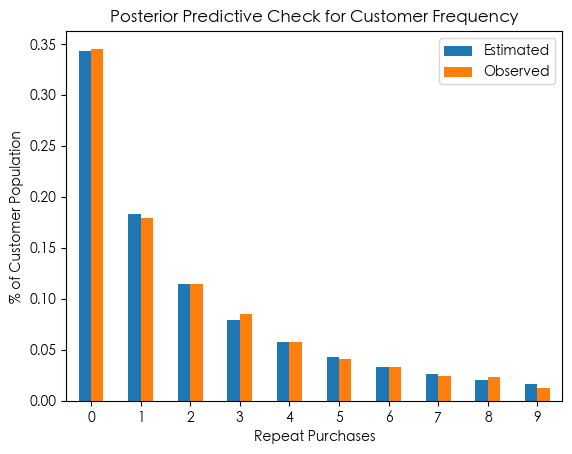

In [88]:
plotting.plot_expected_purchases_ppc(bgm, ppc="posterior")


这个图表示，真实数据确实拟合NBD分布。


## Frequency X Monetary 相关性检验

gamma-gamma 模型有前提假设条件： 

- 客户购买的频率和金额无关。


In [196]:
bgm_data = rfm.query("frequency>1")
# nonzero_data['monetary_value'] = nonzero_data['monetary'] / nonzero_data['frequency']

bgm_data[["monetary_value", "frequency"]].corr()


correlation = bgm_data[['frequency', 'monetary_value']].corr().iloc[0, 1]
print(f"Frequency 与 Monetary Value 的相关系数为: {correlation:.4f}")

Frequency 与 Monetary Value 的相关系数为: 0.0454


✅相关性接近0，不存相关性。

也就是说，可以继续用gamma-gamma 模型来预测客户平均支出，或也称为客户终生价值

# 客户终生价值（CLV）

客户终身价值（CLV 或 LTV）一般是指客户在存续期间内，预计能为企业贡献的总收入


预则立，不立则废。计算出客户终身价值，我们就可以看清单个客户长远能赚多少钱，预测CRM预算；
同时也可以权衡获客成本，评估拉新成本和营销预算……

## Gamma-Gamma 建模




BG/NBD模型主要关注交易的概率和频率，而计算金额可以使用Gamma-Gamma 。

数学结构：

第一层 gamma，描述个体的波动，相当于一个同学每次买零食花费的金额（monetary_value），服从gamma 分布；

第二层 gamma，描述总体的波动，相当于全班同学买零食花费的金额，服从gamma 分布

In [40]:

gg_data = bgm_data[bgm_data["frequency"] > 0].copy() # GG 要求 frequency >0（至少 2 次购买）
ggm = GammaGammaModel(data=gg_data)
ggm.fit()


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [p, q, v]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 9 seconds.


Inference data with groups:
	> posterior
	> sample_stats
	> fit_data

In [ ]:
ggm.fit_summary() 

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
p,2.234,0.128,1.984,2.467,0.004,0.003,1003.0,1373.0,1.0
q,3.533,0.135,3.276,3.789,0.004,0.002,1079.0,1523.0,1.0
v,465.925,41.917,386.778,544.055,1.428,0.897,856.0,987.0,1.0


## 预测平均客单价

模型模拟之后，就可以预测平均客单价，即预测用户每一次购买会带来 多少价值：   

- 群体平均客单价 E[spend] = p*v/(q-1) 

In [42]:
# 平均用户每次购买带来的价值
expected_spend = ggm.expected_customer_spend(data=bgm_data)

az.summary(expected_spend.mean("customer_id"), kind="stats")

,mean,sd,hdi_3%,hdi_97%
x,415.394,3.57,408.738,422.179


客户平均每次购买会带来¥ 415 价值

::: {.callout-tip} 

不论公域、私域还是渠道，首要目标都是“如何获客“，吸引新的客户关注


而现在平台的获客成本越来越高，我们能做是确定获客成本的上限。确定这个上限的方法就是计算客户终生价值，只有让**获客成本<客户终生价值**，才可能盈利。

:::

- 计算新客的消费价值

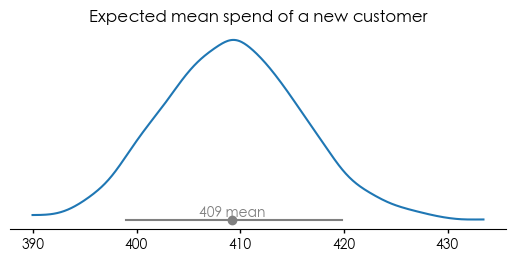

In [ ]:
azp.plot_dist(xr.Dataset({"expected_spend": ggm.expected_new_customer_spend()}))
plt.title("Expected mean spend of a new customer");

预测新客首次交易会带来409左右的销售额

- 计算客户终生价值

In [ ]:
clv_estimate = ggm.expected_customer_lifetime_value(
    transaction_model=bgm,
    data=bgm_data,
    future_t=12,  
    discount_rate=0.01,  
    time_unit="D",
)

az.summary(clv_estimate.mean("customer_id"), kind="stats")

,mean,sd,hdi_3%,hdi_97%
x,1443.374,16.459,1411.897,1473.152


通过差分计算每期增量的购买次数* 客单价，得到未来的购买的总金额 = 1443

In [ ]:
clv_mean = clv_estimate.mean(("chain", "draw")).to_series()  #取均值压成每客户一个值，再按 customer_id 坐标贴回 df

# 获得每个客户的clv点估计
rfm_clv = rfm.merge(  
    clv_mean.rename("clv_estimate"),  
    left_on="customer_id",  
    right_index=True,  
    how="left",  
)

对10位用户的CLV分布进行可视化

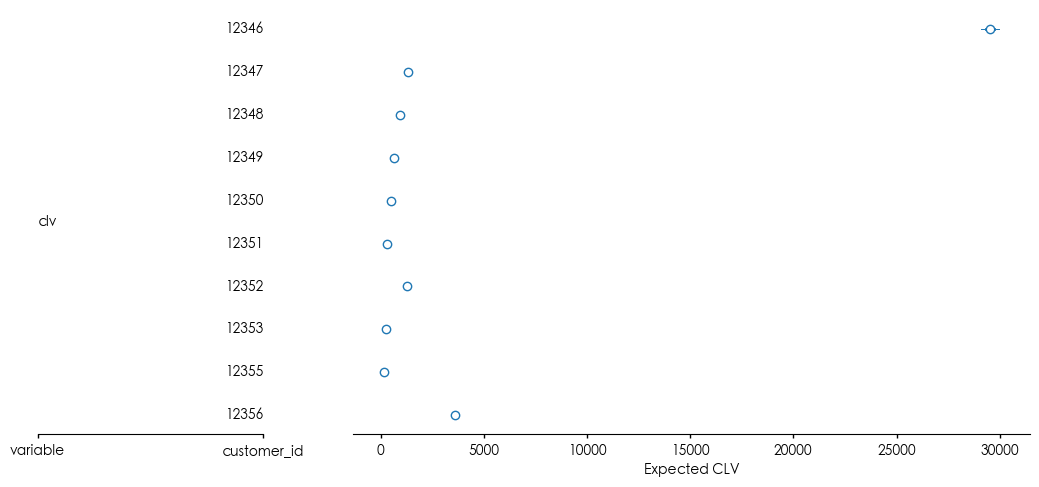

In [ ]:

# 观察10位用户的CLV分布
labeller = MapLabeller(var_name_map={"x": "customer"})

azp.plot_forest(
    xr.Dataset({"clv": clv_estimate.isel(customer_id=range(10))}),
    combined=True,
    labeller=labeller,
)
plt.xlabel("Expected CLV");

这张图再次展现了客户间购买的具有极大的差异性

## 分层 x CLV 对比

最后我们将重新回顾用户分层

这次使用KMeans 聚类 来重新进行用户分层

In [ ]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

SEED = 42
K = 5

# 聚类仅基于历史 R/F/M 特征，未使用模型预测值。
# 预处理：log1p + MinMaxScaler
X = MinMaxScaler().fit_transform(np.column_stack([
    np.log1p(rfm_clv["frequency"]),
    np.log1p(rfm_clv["monetary_value"]),
    -np.log1p(rfm_clv["recency"]),
]))

km = KMeans(n_clusters=K, random_state=SEED, n_init=10).fit(X)
rfm_clv["Cluster"] = km.labels_

In [169]:
prof = rfm_clv.groupby("Cluster").agg(
    客户数=("customer_id", "size"),
    R中位=("recency", "median"), 
    F中位=("frequency", "median"),
    M中位=("monetary_value", "median"),
    人均CLV=("clv_estimate", "mean"))
    # 存活概率=("p_alive", "mean")).round(1)
prof["客户占比%"] = (prof["客户数"] / prof["客户数"].sum() * 100).round(1)
prof["消费占比%"] = (rfm_clv.groupby("Cluster")["monetary_value"].sum() /
                     rfm_clv["monetary_value"].sum() * 100).round(1)

display(prof.sort_values('人均CLV'))

,客户数,R中位,F中位,M中位,人均CLV,客户占比%,消费占比%
Cluster,,,,,,,
2,1981,421.0,1.0,229.330000,434.959560,33.8,28.7
3,1209,36.0,2.0,283.525000,529.457271,20.6,18.6
0,1033,178.0,4.0,302.530000,1101.357302,17.6,17.4
4,963,31.0,9.0,343.022000,2021.518206,16.4,17.8
1,675,4.0,11.0,349.252222,5234.553886,11.5,17.5


聚类的方法提供了所分的类，但是不能为我们提出业务命名，这些聚出来类别就像旅行者号拍摄到新发现的行星系图片，需要人类为他们决策命名。

对数据的值进行排名，可以总结出以下这个类别标签：

- 1 核心高价值
- 2 流失
- 3 新客
- 4 中高频·价值稳定
- 0 一般保持

In [178]:
# 倾向命名的标签：
label_map = {
    0: "一般保持",
    1: "核心高价值",
    2: "流失",
    3: "新客",
    4: "中高频·价值稳定",
   
}

prof["ClusterLabel"] = prof.index.map(label_map)
order = prof.sort_values("M中位", ascending=False).index.tolist()
prof.sort_values("人均CLV", ascending=False)


,客户数,R中位,F中位,M中位,人均CLV,客户占比%,消费占比%,ClusterLabel
Cluster,,,,,,,,
1,675,4.0,11.0,349.252222,5234.553886,11.5,17.5,核心高价值
4,963,31.0,9.0,343.022000,2021.518206,16.4,17.8,中高频·价值稳定
0,1033,178.0,4.0,302.530000,1101.357302,17.6,17.4,一般保持
3,1209,36.0,2.0,283.525000,529.457271,20.6,18.6,新客
2,1981,421.0,1.0,229.330000,434.959560,33.8,28.7,流失


In [190]:
rfm_clv[rfm_clv['customer_id']==15411]

,index,customer_id,frequency,recency,monetary_value,R,F,M,RFM_Score,clv_estimate,Cluster
3020,3020,15411,4.0,26.0,337.2325,4,4,4,444,NaN,3


In [ ]:
#| column: page  
import plotly.graph_objects as go

PAL = ["#C0392B", "#E67E22", "#F1C40F", "#27AE60", "#2980B9"]
color = {c: PAL[i % len(PAL)] for i, c in enumerate(order)}

f_ticks = [0, 1, 2, 5, 10, 20, 50, 100]
m_ticks = [0, 10, 50, 100, 500, 1000, 5000, 10000]
r_ticks = [0, 1, 7, 30, 90, 180, 365, 700]

f_tv, f_tt = ticks(rfm_clv["frequency"], f_ticks)
m_tv, m_tt = ticks(rfm_clv["monetary_value"], m_ticks)
r_tv, r_tt = ticks(rfm_clv["recency"], r_ticks)


def hover(r):
    return (f"客户 {r['customer_id']}<br>"
            f"Frequency: {r['frequency']:,.0f} 单<br>"
            f"Monetary: {r['monetary_value']:,.0f}<br>"
            f"Recency: {r['recency']:,.0f} 天<br>"
            f"CLV: {r['clv_estimate']:,.0f} <br>"
            )

fig = go.Figure()
for c in order:
    g = rfm_clv[rfm_clv["Cluster"] == c]
    fig.add_trace(go.Scatter3d(
        x=np.log1p(g["frequency"]),
        y=np.log1p(g["monetary_value"]),
        z=-np.log1p(g["recency"]),          # recency = 距今天数，取负号后越大越近
        mode="markers",
        name=f"{c} · {label_map[c]}（n={len(g):,}）",
        marker=dict(size=2.5, color=color[c], opacity=0.35),
        customdata=np.stack([g["frequency"], g["monetary_value"],
                             g["recency"], g["clv_estimate"]], -1),
        hovertemplate=g.apply(hover, axis=1), 
    ))

fig.update_layout(
    height=760, margin=dict(l=0, r=0, t=30, b=0),
    legend=dict(itemsizing="constant"),
    scene=dict(
            xaxis=axis_cfg("Frequence", f_tv, f_tt), 
            yaxis=axis_cfg("Monetary_value", m_tv, m_tt), 
            zaxis=axis_cfg("-Recency", r_tv, r_tt, neg=True), 
            aspectmode="cube"
        ),
    title=dict(
            text="Online Retail II · RFM 聚类分层", 
            x=0.5, font=dict(size=15)
        ),
)
fig.show()


对照同一层内的CLV , 发现"看起来的高价值用户"不等于"未来高价值"，

仅依据 RFM 标签用户分层可能存在极大的不确定性。

结合CLV的结果 ，可以找出"高价值但被忽视"的群体，提前干预或者进行营销投放“刷存在感“。

::: {.callout-tip} 

我们要以最小投资，获取最多顾客，这是所有人共同的目标。很多人觉得做用户定位可以找到核心用户，可以抓取特殊用户进行营销，但实际上用户定位只和产品本身有关。一个行业的消费品和另一个行业的消费品，在人口特征分布（demographic）几乎没有任何区别。也就是说，所有的客户都是一群人，所有流失的模型都是跨行业的，您可以完全将这些模型运用于你自己的数据。

:::

# 致谢：

谢谢你愿意认真读完所有内容，希望这些对你有帮助。




In [143]:
%load_ext watermark

In [144]:

%watermark -n -u -v -iv -h -w -p pymc,pytensor


Last updated: Wed, 04 Nov 2026

Python implementation: CPython
Python version       : 3.10.10
IPython version      : 8.39.0

pymc    : 5.25.1
pytensor: 2.31.7

Hostname: siyingdeMacBook-Pro.local

arviz         : 0.23.4
arviz_base    : 0.3.0
arviz_plots   : 0.3.0
lifetimes     : 0.11.3
matplotlib    : 3.10.9
numpy         : 1.26.4
pandas        : 2.3.3
plotly        : 6.9.0
pymc_marketing: 0.15.1
seaborn       : 0.13.2
sklearn       : 1.7.2
xarray        : 2024.9.0

Watermark: 2.6.0

